In [ ]:
from transformers import AutoTokenizer
import torch

# Day 1

In [ ]:
model_name = "distilbert-base-uncased"

In [ ]:
# for Russian
# model_name = "distilbert-base-multilingual-cased"

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(model_name)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
print(tokenizer.vocab_size)
print(tokenizer.model_max_length)

30522
512


### Task 3

In [ ]:
text = "This movie was absolutely amazing!"

In [ ]:
tokens = tokenizer(text)
print(tokens)

{'input_ids': [101, 2023, 3185, 2001, 7078, 6429, 999, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}


In [ ]:
input_ids = tokens['input_ids']
print(f'Количество токенов: {len(input_ids)}')

Количество токенов: 8


In [ ]:
decoded = tokenizer.decode(input_ids)
print(f'Декодировано: {decoded}')

Декодировано: [CLS] this movie was absolutely amazing! [SEP]


### Task 4

In [ ]:
def tokenize_texts(texts, max_length=128):
    return tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt"
    )

In [ ]:
texts = [
    "This movie was great!",
    "Terrible movie, waste of time."
]

tokens = tokenize_texts(texts)
print(f'Shape: {tokens["input_ids"].shape}')

Shape: torch.Size([2, 9])


In [ ]:
print(f'Attention mask:\n{tokens["attention_mask"]}')

Attention mask:
tensor([[1, 1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1]])


### Task 5

In [ ]:
print(f'CLS token: {tokenizer.cls_token} (ID: {tokenizer.cls_token_id})')
print(f'SEP token: {tokenizer.sep_token} (ID: {tokenizer.sep_token_id})')
print(f'PAD token: {tokenizer.pad_token} (ID: {tokenizer.pad_token_id})')

CLS token: [CLS] (ID: 101)
SEP token: [SEP] (ID: 102)
PAD token: [PAD] (ID: 0)


In [ ]:
single = tokenizer(text, return_tensors="pt")
print(f'Input IDs: {single["input_ids"]}')
print(f'Decoded: {tokenizer.decode(single["input_ids"][0])}')

Input IDs: tensor([[ 101, 2023, 3185, 2001, 7078, 6429,  999,  102]])
Decoded: [CLS] this movie was absolutely amazing! [SEP]


### Task 6

In [ ]:
def explain_tokenization(text, tokenizer):
    tokens = tokenizer.tokenize(text)
    ids = tokenizer.convert_tokens_to_ids(tokens)

    print(f'Исходный текст: {text}')
    print(f'Токены: {tokens}')
    print(f'IDs: {ids}')
    print(f'Количество: {len(tokens)}')

In [ ]:
# Протестируйте:
explain_tokenization("Transformers are amazing!", tokenizer)

Исходный текст: Transformers are amazing!
Токены: ['transformers', 'are', 'amazing', '!']
IDs: [19081, 2024, 6429, 999]
Количество: 4


# Day 2

### Task 1

In [ ]:
from transformers import AutoModel

In [ ]:
model = AutoModel.from_pretrained(model_name)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
model.eval()

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [ ]:
print(model)

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

### Task 2

In [ ]:
text = "This movie was absolutely amazing!"
tokens = tokenizer(text, return_tensors="pt")

In [ ]:
with torch.no_grad():
    outputs = model(**tokens)

In [ ]:
print(type(outputs))
print(outputs.last_hidden_state.shape)

<class 'transformers.modeling_outputs.BaseModelOutput'>
torch.Size([1, 8, 768])


In [ ]:
cls_embedding = outputs.last_hidden_state[:, 0, :]
print(f'CLS embedding shape: {cls_embedding.shape}')
print(f'CLS embedding: {cls_embedding[0][:5]}...')  # первые 5 значений

CLS embedding shape: torch.Size([1, 768])
CLS embedding: tensor([ 0.0682, -0.0685,  0.1918,  0.0139, -0.0544])...


### Task 3

In [ ]:
import numpy as np

In [ ]:
def get_embeddings(texts, tokenizer, model, batch_size=32):
    all_embeddings = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i+batch_size]

        # Токенизируем (используем функцию из Дня 1)
        tokens = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        )

        # Получаем hidden states
        with torch.no_grad():
            outputs = model(**tokens)

        # Извлекаем CLS-токены
        cls_embeddings = outputs.last_hidden_state[:, 0, :]
        all_embeddings.append(cls_embeddings.cpu().numpy())

    # Объединяем все батчи
    return np.vstack(all_embeddings)

### Task 4

In [ ]:
texts = [
    "This movie was absolutely amazing!",
    "Terrible movie, waste of time.",
    "Pretty good, I liked it.",
    "Boring and too long."
]

In [ ]:
embeddings = get_embeddings(texts, tokenizer, model)
print(f'Embeddings shape: {embeddings.shape}')
print(f'Ожидается: (4, 768) для DistilBERT')

Embeddings shape: (4, 768)
Ожидается: (4, 768) для DistilBERT


### Task 5

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
def similarity(text1, text2, tokenizer, model):
    emb = get_embeddings([text1, text2], tokenizer, model)
    sim = cosine_similarity(emb[0:1], emb[1:2])[0][0]
    return sim

In [ ]:
sim1 = similarity("Great movie!", "Amazing film!", tokenizer, model)
sim2 = similarity("Great movie!", "Terrible film!", tokenizer, model)

print(f'Сходство похожих: {sim1:.3f}')
print(f'Сходство разных: {sim2:.3f}')

Сходство похожих: 0.995
Сходство разных: 0.984


# Day 3

### Task 1

In [ ]:
model = AutoModel.from_pretrained(
    model_name,
    output_attentions=True  # важно!
)
model.eval()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [ ]:
text = "The amazing movie won many awards"
tokens = tokenizer(text, return_tensors='pt')

### Task 2

In [ ]:
with torch.no_grad():
    outputs = model(**tokens)

In [ ]:
print(type(outputs.attentions))
print(f'Количество слоёв: {len(outputs.attentions)}')
print(f'Форма attention для слоя 0: {outputs.attentions[0].shape}')

<class 'tuple'>
Количество слоёв: 6
Форма attention для слоя 0: torch.Size([1, 12, 8, 8])


In [ ]:
attention = outputs.attentions[0]  # первый слой
print(f'Attention shape: {attention.shape}')

Attention shape: torch.Size([1, 12, 8, 8])


In [ ]:
# Для первого батча, первой головы
attn_single = attention[0, 0]  # [seq_len, seq_len]
print(f'Single head shape: {attn_single.shape}')

Single head shape: torch.Size([8, 8])


### Task 3

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
def visualize_attention(tokens, attention, layer=0, head=0):
    """
    tokens: токенизированный текст
    attention: attention weights от модели
    layer: номер слоя для визуализации
    head: номер головы для визуализации
    """
    # Получаем attention матрицу
    attn = attention[layer][0, head]  # [seq_len, seq_len]

    # Получаем токены для подписей
    token_list = tokenizer.convert_ids_to_tokens(tokens['input_ids'][0])

    # Рисуем heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        attn.cpu().numpy(),
        xticklabels=token_list,
        yticklabels=token_list,
        cmap='viridis',
        cbar=True
    )
    plt.title(f'Attention - Layer {layer}, Head {head}')
    plt.xlabel('Keys')
    plt.ylabel('Queries')
    plt.tight_layout()
    plt.savefig(f'attention_layer{layer}_head{head}.png')
    plt.show()

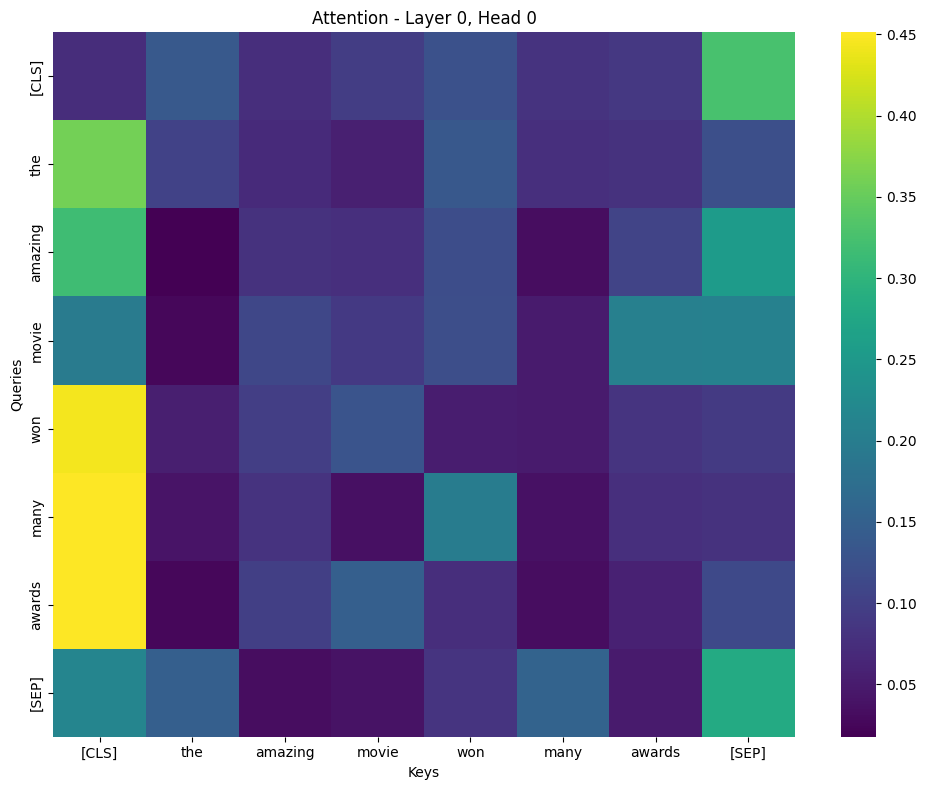

In [ ]:
# Используйте:
visualize_attention(tokens, outputs.attentions, layer=0, head=0)

### Task 4

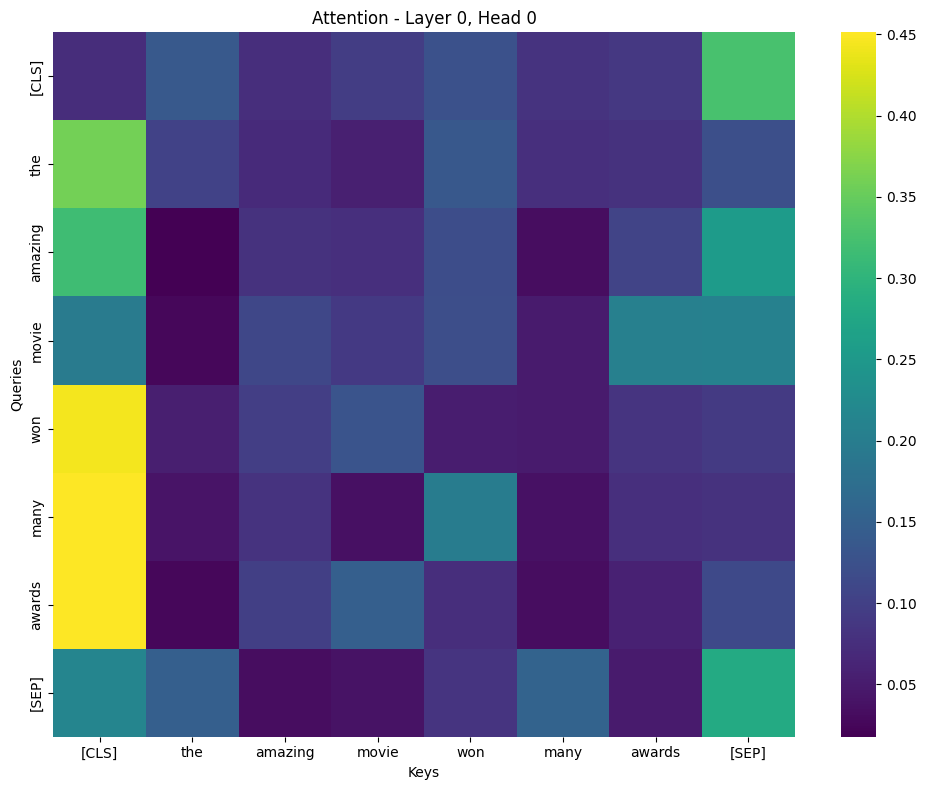

In [ ]:
# Первый слой
visualize_attention(tokens, outputs.attentions, layer=0, head=0)

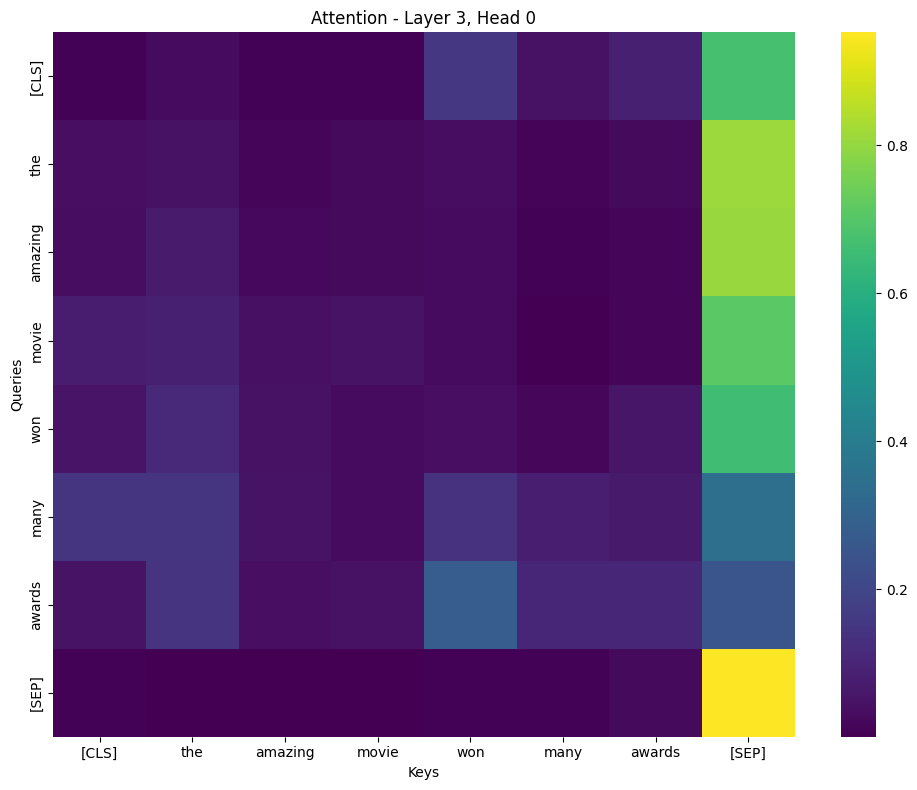

In [ ]:
# Средний слой
visualize_attention(tokens, outputs.attentions, layer=3, head=0)

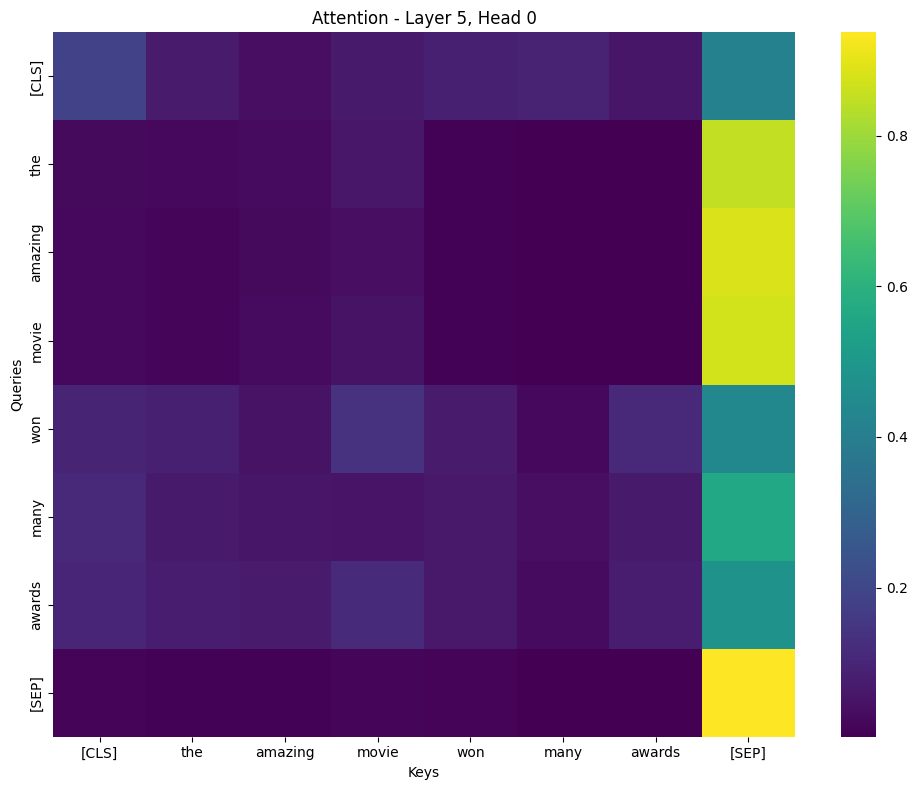

In [ ]:
# Последний слой
visualize_attention(tokens, outputs.attentions, layer=5, head=0)

### Task 5

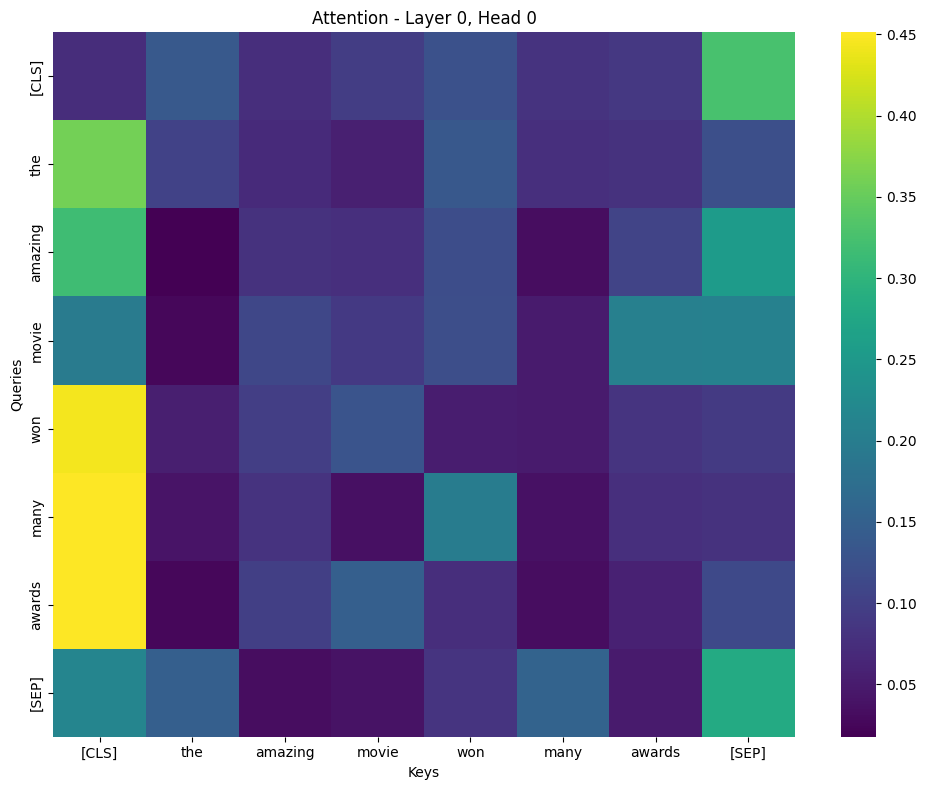

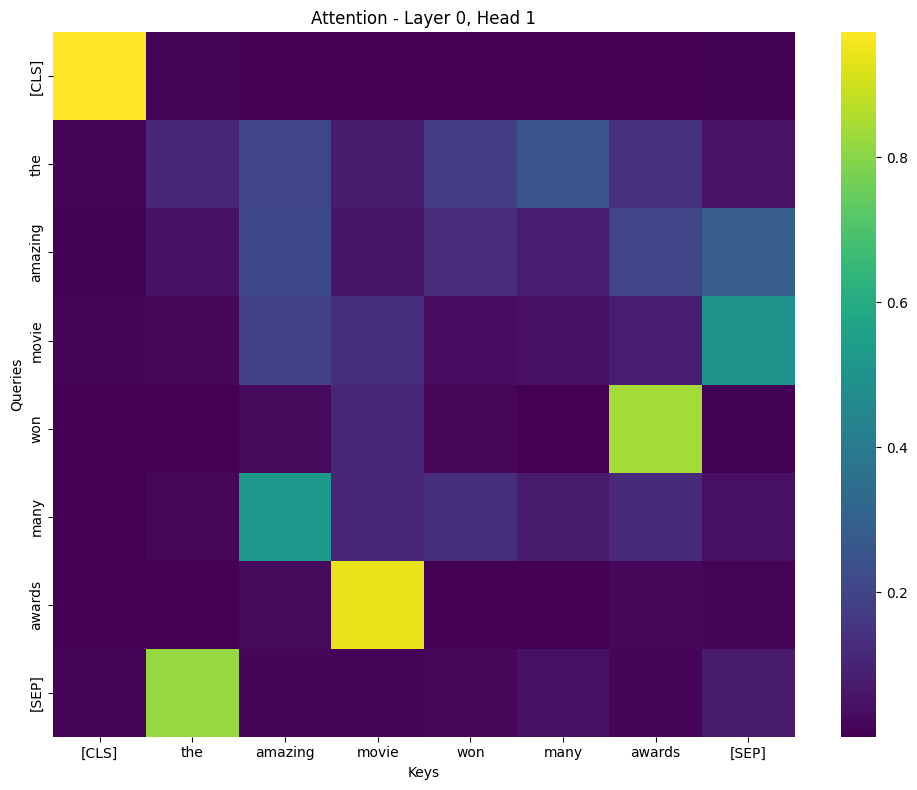

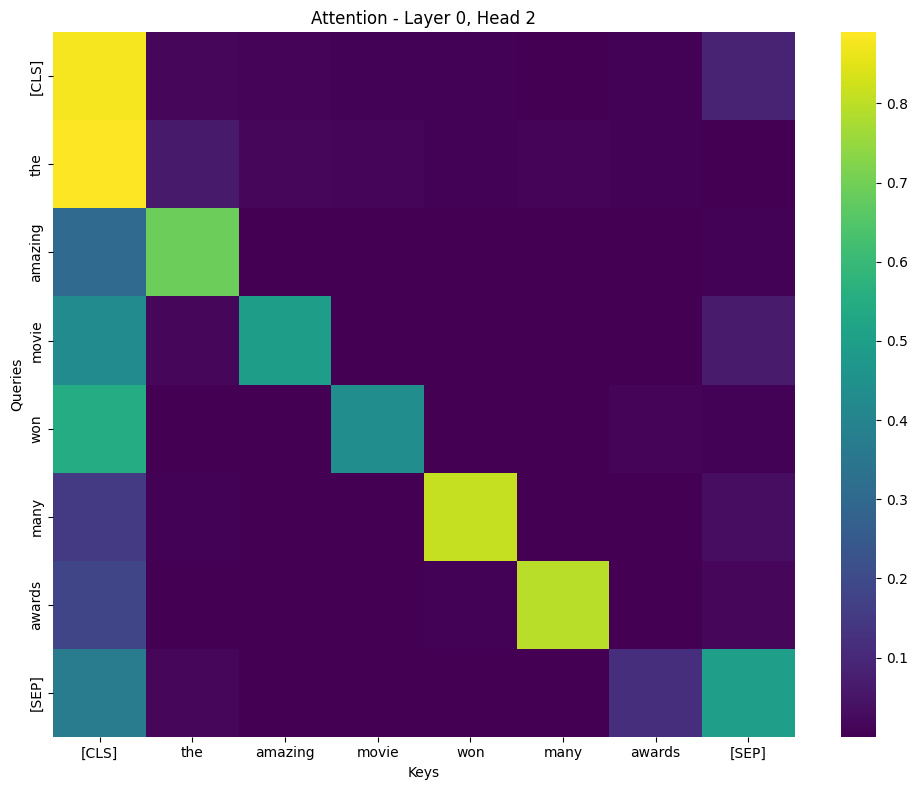

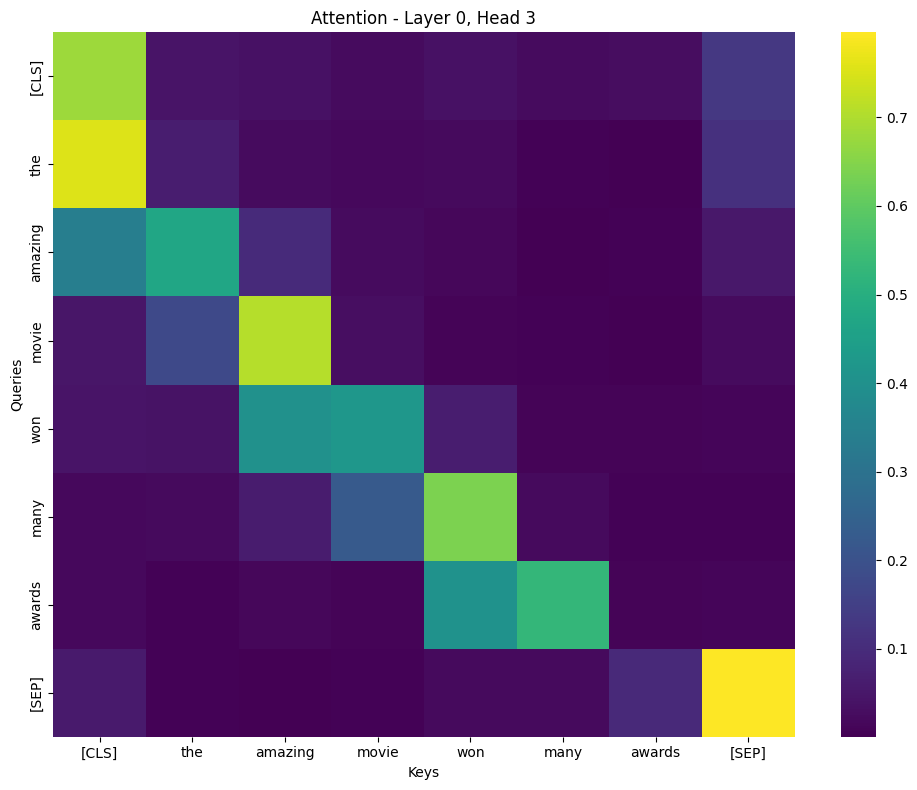

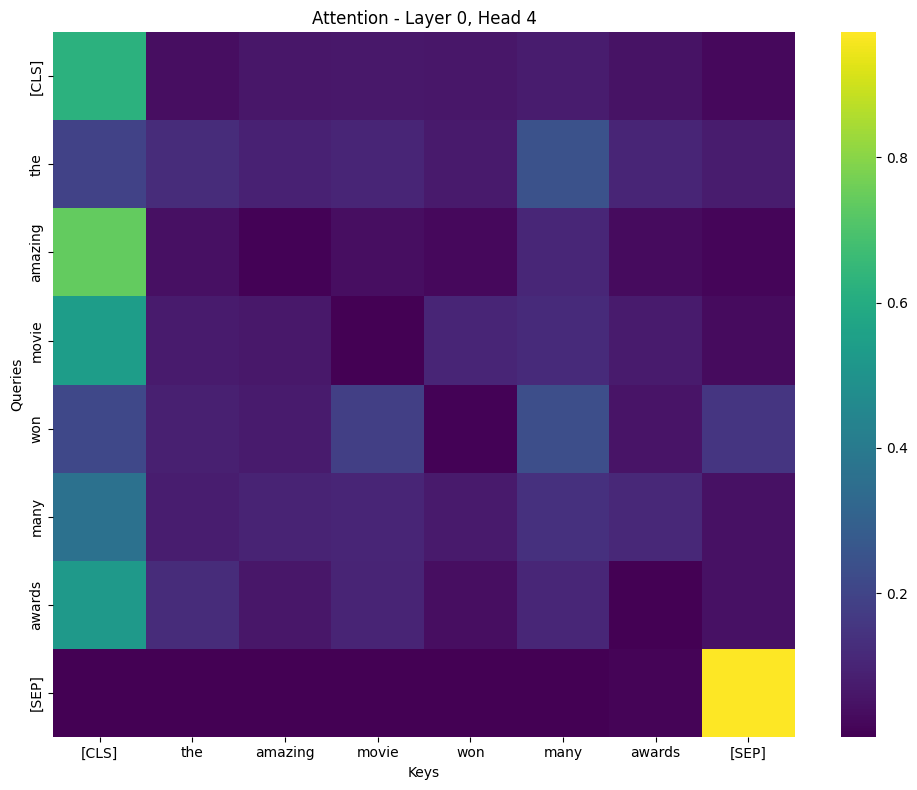

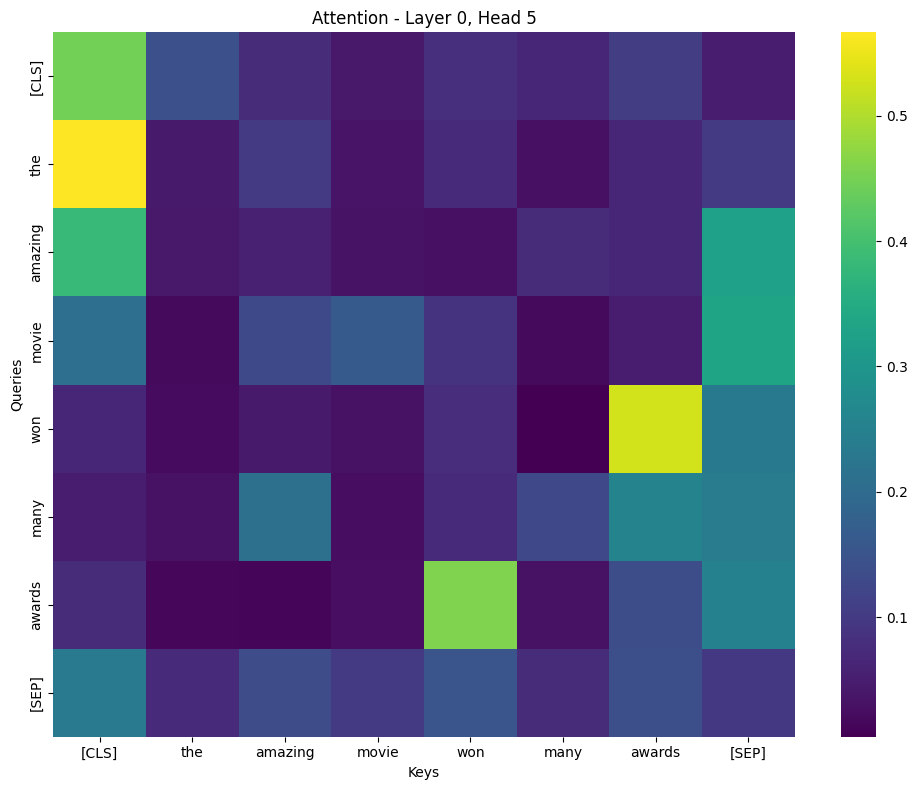

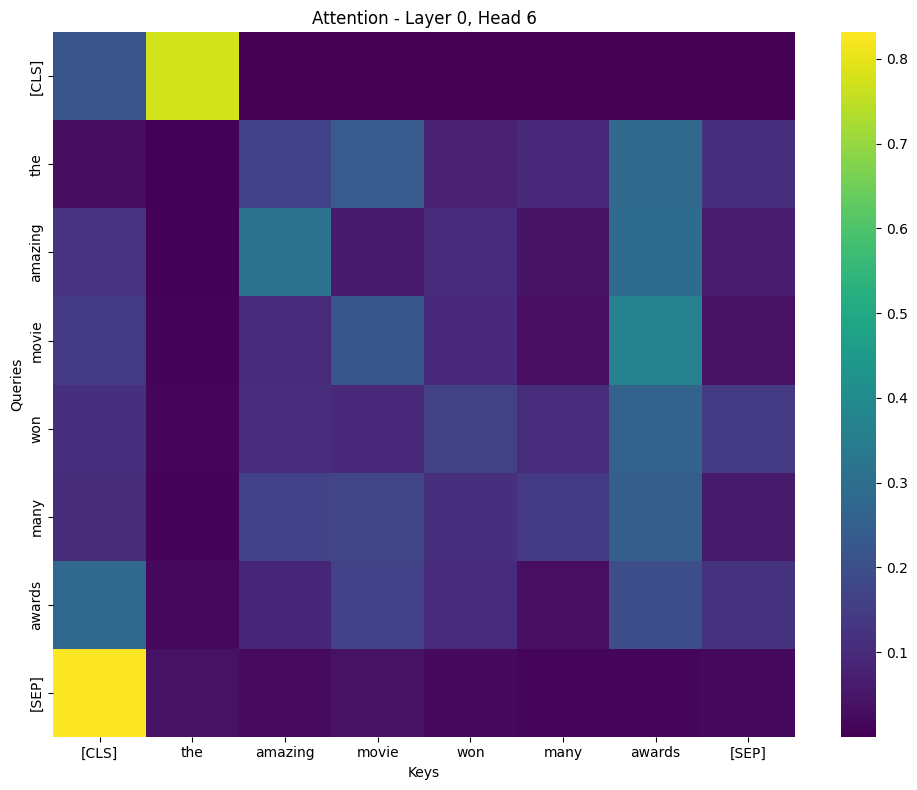

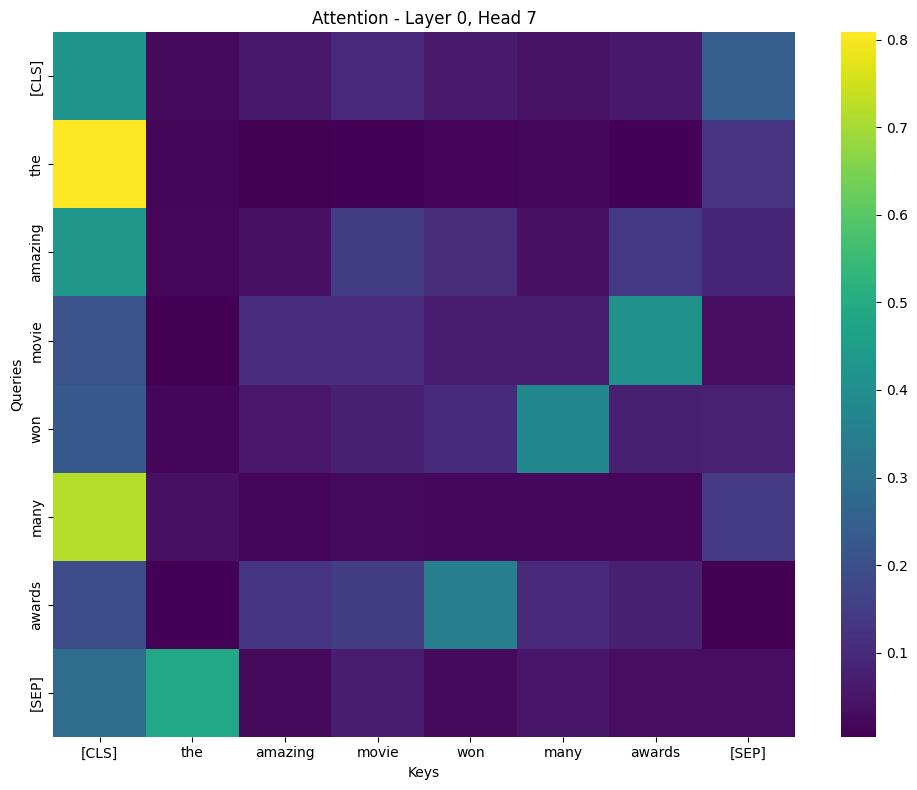

In [ ]:
for head in range(8):  # DistilBERT имеет 8 голов
    visualize_attention(tokens, outputs.attentions, layer=0, head=head)

In [ ]:
### В разных головах действительно разные взаимосвязи между токенами

### Task 6

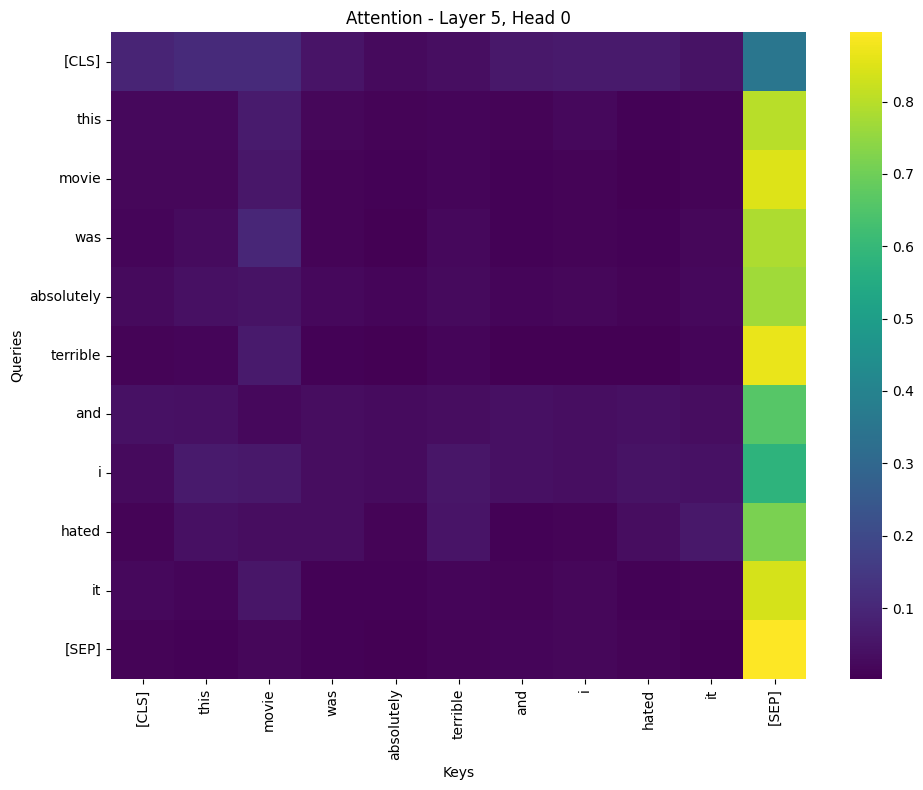

In [ ]:
text = "This movie was absolutely terrible and I hated it"
tokens = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    outputs = model(**tokens)

# Визуализируйте
visualize_attention(tokens, outputs.attentions, layer=5, head=0)

In [ ]:
# у terrible фокус на movie

# Day 4

### Task 1

In [ ]:
from transformers import AutoTokenizer

In [ ]:
model_name='distilbert-base-uncased'

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [ ]:
def tokenize_texts(texts, max_length=128):
    tokenized = tokenizer(texts,
                                padding=True,
                                truncation=True,
                                max_length=max_length,
                                return_tensors="pt")
    return tokenized

In [ ]:
texts = [
    "This movie was absolutely amazing!",
    "Terrible movie, waste of time.",
    "Pretty good, I liked it.",
    "Boring and too long."
]

In [ ]:
tokenize_texts(texts)

{'input_ids': tensor([[  101,  2023,  3185,  2001,  7078,  6429,   999,   102,     0],
        [  101,  6659,  3185,  1010,  5949,  1997,  2051,  1012,   102],
        [  101,  3492,  2204,  1010,  1045,  4669,  2009,  1012,   102],
        [  101, 11771,  1998,  2205,  2146,  1012,   102,     0,     0]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 0, 0]])}

### Task 2

In [ ]:
from transformers import AutoModel
import torch

In [ ]:
model = AutoModel.from_pretrained(model_name)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [ ]:
model.eval()

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [ ]:
def get_cls_embeddings(texts, batch_size=32):
    all_embeddings = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i+batch_size]
        tokens = tokenizer(batch_texts,
                           padding=True,
                           truncation=True,
                           max_length=128,
                           return_tensors='pt')

        with torch.no_grad():
            outputs = model(**tokens)

        cls_embeddings = outputs.last_hidden_state[:, 0, :]
        all_embeddings.append(cls_embeddings.cpu().numpy())

    return np.vstack(all_embeddings)

In [ ]:
get_cls_embeddings(texts)

array([[ 0.0682217 , -0.06854336,  0.191839  , ..., -0.18599835,
         0.39768815,  0.21738122],
       [ 0.00339733, -0.04019894, -0.00593701, ..., -0.2512241 ,
         0.39587745,  0.1626431 ],
       [-0.06282155, -0.12721898,  0.04524286, ..., -0.10008843,
         0.19173197,  0.24091008],
       [-0.05920605, -0.22124729,  0.07999265, ..., -0.05016081,
         0.36998236,  0.15315346]], shape=(4, 768), dtype=float32)

In [ ]:
# размерность верная

### Task 3

In [ ]:
# используем IMDB

In [ ]:
from datasets import load_dataset
import pandas as pd

In [ ]:
# Load the dataset from Hugging Face
dataset = load_dataset("stanfordnlp/imdb")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [ ]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [ ]:
from tqdm.auto import tqdm

In [ ]:
# переписал на gpu, т.к. на cpu долго
def get_cls_embeddings(texts, batch_size=128):

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model.to(device)
    model.eval()

    all_embeddings = []

    for i in tqdm(range(0, len(texts), batch_size)):

        batch_texts = texts[i:i + batch_size]

        # Tokenization
        tokens = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt",
            pad_to_multiple_of=8
        )

        # Move inputs to GPU
        tokens = {k: v.to(device) for k, v in tokens.items()}

        # FP16 inference on T4
        with torch.inference_mode():
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                outputs = model(**tokens)

                cls_embeddings = outputs.last_hidden_state[:, 0, :]

        all_embeddings.append(cls_embeddings.cpu())

    return torch.cat(all_embeddings, dim=0).numpy()


In [ ]:
texts = dataset["train"]["text"]
labels = np.asarray(dataset["train"]["label"])

X_train = get_cls_embeddings(texts)

  0%|          | 0/196 [00:00<?, ?it/s]

In [ ]:
texts_test = dataset["test"]["text"]
labels_test = np.asarray(dataset["test"]["label"])

X_test = get_cls_embeddings(texts_test)

  0%|          | 0/196 [00:00<?, ?it/s]

In [ ]:
dataset['train']

Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})

In [ ]:
train_texts = dataset["train"]["text"]
test_texts = dataset["test"]["text"]

y_train = dataset["train"]["label"]
y_test = dataset["test"]["label"]

In [ ]:
embedding_columns = [
    f"emb_{i}" for i in range(X_train.shape[1])
]

train_df = pd.DataFrame(X_train, columns=embedding_columns)
train_df["text"] = train_texts
train_df["label"] = y_train

test_df = pd.DataFrame(X_test, columns=embedding_columns)
test_df["text"] = test_texts
test_df["label"] = y_test

In [ ]:
df_full = pd.concat([train_df, test_df], axis=0)
df_full = df_full.reset_index(drop=True)

In [ ]:
df_full.shape

(50000, 770)

In [ ]:
from sklearn.model_selection import train_test_split


In [ ]:
df_train, df_test = train_test_split(
    df_full,
    test_size=0.2,
    random_state=42,
    stratify=df_full["label"]
)

In [ ]:
df_train.shape, df_test.shape

((40000, 770), (10000, 770))

In [ ]:
X_train = df_train[embedding_columns]
X_test = df_test[embedding_columns]

y_train = df_train["label"]
y_test = df_test["label"]

In [ ]:
print("Train:", df_train.shape)
print("Test:", df_test.shape)

print("\nTrain label distribution:")
print(df_train["label"].value_counts(normalize=True))

print("\nTest label distribution:")
print(df_test["label"].value_counts(normalize=True))

Train: (40000, 770)
Test: (10000, 770)

Train label distribution:
label
1    0.5
0    0.5
Name: proportion, dtype: float64

Test label distribution:
label
0    0.5
1    0.5
Name: proportion, dtype: float64


In [ ]:
from sklearn.linear_model import LogisticRegression

X_train = df_train[embedding_columns]
X_test = df_test[embedding_columns]

logreg = LogisticRegression(max_iter=1000, n_jobs=-1)

logreg.fit(X_train, y_train)

LogisticRegression(max_iter=1000, n_jobs=-1)

In [ ]:
from sklearn.metrics import classification_report, f1_score

In [ ]:
y_pred = logreg.predict(X_test)

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.83      0.82      5000
           1       0.83      0.81      0.82      5000

    accuracy                           0.82     10000
   macro avg       0.82      0.82      0.82     10000
weighted avg       0.82      0.82      0.82     10000



In [ ]:
f1 = f1_score(y_test, y_pred, average='macro')

In [ ]:
f1

0.8212763637991125

In [ ]:
with open("baseline_results.txt", "w") as f:
    f.write("Baseline: BERT CLS + Logistic Regression\n")
    f.write("----------------------------------------\n")
    f.write(f"Macro F1: {f1:.4f}\n\n")
    f.write("Classification Report:\n")
    f.write(classification_report(y_test, y_pred))

In [ ]:
import joblib

joblib.dump(logreg, "baseline_model.pkl")

['baseline_model.pkl']

# Day 5

### Task 1

In [ ]:
from torch.utils.data import Dataset

In [ ]:
class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]

        encoding = self.tokenizer(
            text,
            padding='max_length',
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

### Task 2

In [ ]:
# Load the dataset from Hugging Face
dataset = load_dataset("stanfordnlp/imdb")

In [ ]:
train_texts = dataset["train"]["text"]
test_texts = dataset["test"]["text"]

y_train = dataset["train"]["label"]
y_test = dataset["test"]["label"]

In [ ]:
import pandas as pd

# df = pd.read_csv('your_dataset.csv')
# texts = df['text'].tolist()
# labels = df['label'].tolist()

df = pd.DataFrame({
    "text": list(train_texts) + list(test_texts),
    "label": list(y_train) + list(y_test)
})

texts = df['text'].tolist()
labels = df['label'].tolist()

In [ ]:
from sklearn.model_selection import train_test_split

train_texts, val_texts, train_labels, val_labels = train_test_split(
    texts, labels, test_size=0.2, random_state=42, stratify=labels
)

In [ ]:
train_dataset = SentimentDataset(train_texts, train_labels, tokenizer)
val_dataset = SentimentDataset(val_texts, val_labels, tokenizer)

### Task 3

In [ ]:
from transformers import AutoModelForSequenceClassification

# Определите количество классов
num_labels = len(set(labels))  # 2 для бинарной, 3 для positive/negative/neutral

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=num_labels
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16)

### Task 4

In [ ]:
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score

In [ ]:
optimizer = AdamW(model.parameters(), lr=2e-5)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

### Task 5

In [ ]:
def train_epoch(model, dataloader, optimizer, device):
    model.train()
    total_loss = 0

    for batch in tqdm(dataloader):
        optimizer.zero_grad()

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(
          input_ids=input_ids,
          attention_mask=attention_mask,
          labels=labels
        )

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)

### Task 6

In [ ]:
def evaluate(model, dataloader, device):
    model.eval()
    predictions = []
    true_labels = []

    with torch.no_grad():
        for batch in tqdm(dataloader):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            preds = torch.argmax(outputs.logits, dim=1)
            predictions.extend(preds.cpu().numpy())
            true_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(true_labels, predictions)
    f1 = f1_score(true_labels, predictions, average='macro')

    return accuracy, f1

### Task 7

In [ ]:
num_epochs = 3

for epoch in range(num_epochs):
    train_loss = train_epoch(model, train_loader, optimizer, device)
    val_acc, val_f1 = evaluate(model, val_loader, device)

    print(f'Epoch {epoch+1}/{num_epochs}')
    print(f'Train Loss: {train_loss:.4f}')
    print(f'Val Accuracy: {val_acc:.4f}')
    print(f'Val F1: {val_f1:.4f}')
    print('-' * 50)

  0%|          | 0/2500 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 1/3
Train Loss: 0.3304
Val Accuracy: 0.8829
Val F1: 0.8827
--------------------------------------------------


  0%|          | 0/2500 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 2/3
Train Loss: 0.2068
Val Accuracy: 0.8725
Val F1: 0.8717
--------------------------------------------------


  0%|          | 0/2500 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 3/3
Train Loss: 0.1131
Val Accuracy: 0.8877
Val F1: 0.8876
--------------------------------------------------


### Task 8

In [ ]:
model.save_pretrained('./fine_tuned_model')
tokenizer.save_pretrained('./fine_tuned_model')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./fine_tuned_model/tokenizer_config.json',
 './fine_tuned_model/tokenizer.json')

In [ ]:
with open('fine_tuned_results.txt', 'w') as f:
    f.write(f'Final Validation F1: {val_f1:.4f}\n')
    f.write(f'Final Validation Accuracy: {val_acc:.4f}\n')

# Day 6

### Task 1

In [ ]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer
import torch

In [ ]:
model_ft = AutoModelForSequenceClassification.from_pretrained('./fine_tuned_model')
tokenizer = AutoTokenizer.from_pretrained('./fine_tuned_model')
model_ft.eval()

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [ ]:
import joblib

In [ ]:
# Если вы сохранили baseline модель
baseline_model = joblib.load('baseline_model.pkl')
baseline_vectorizer = joblib.load('vectorizer.pkl')

FileNotFoundError: [Errno 2] No such file or directory: 'vectorizer.pkl'

In [ ]:
X_train,X_test

(          emb_0     emb_1     emb_2     emb_3     emb_4     emb_5     emb_6  \
 48903  0.203409 -0.149036  0.023082 -0.115984  0.022002 -0.100078  0.238980   
 10174  0.109783 -0.126081 -0.169394 -0.139875 -0.161638 -0.413216  0.171407   
 34019 -0.195704 -0.120561 -0.096965 -0.154130  0.088598  0.024668  0.137563   
 9815   0.280636 -0.152255  0.040737 -0.051248 -0.160779 -0.147838  0.158419   
 6895   0.247690 -0.091093 -0.210894 -0.092745  0.002820 -0.248052  0.220615   
 ...         ...       ...       ...       ...       ...       ...       ...   
 40542 -0.011274 -0.273498 -0.111476 -0.226637  0.110840 -0.069421  0.199526   
 11522  0.127010 -0.037281 -0.227383 -0.041902  0.000971 -0.189303  0.115703   
 36243  0.112433 -0.260857  0.033907 -0.184278 -0.018509 -0.206126  0.380434   
 30299  0.047954 -0.116014 -0.193627 -0.078731  0.012999 -0.157811  0.273412   
 26224  0.149639 -0.089741 -0.095362 -0.058836 -0.112561 -0.345048  0.149815   
 
           emb_7     emb_8     emb_9  

### Task 2

In [ ]:
def predict_fine_tuned(texts, model, tokenizer):
    if isinstance(texts, str):
        texts = [texts]

    predictions = []

    for text in tqdm(texts):
        inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=128)

        with torch.no_grad():
            outputs = model(**inputs)

        probs = torch.nn.functional.softmax(outputs.logits, dim=1)
        pred = torch.argmax(probs, dim=1).item()

        predictions.append({
            'text': text,
            'prediction': pred,
            'probabilities': probs[0].cpu().numpy()
        })

    return predictions

### Task 3

In [ ]:
model_name='distilbert-base-uncased'
model_vec=AutoModel.from_pretrained(model_name)
model_vec.eval()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [ ]:
tokenizer_vec = AutoTokenizer.from_pretrained(model_name)

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
class CLSVectorizer(BaseEstimator, TransformerMixin):

    def __init__(self, tokenizer, model, batch_size=128, max_length=128):
        self.tokenizer = tokenizer
        self.model = model
        self.batch_size = batch_size
        self.max_length = max_length
        self.device = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

    def fit(self, X, y=None):
        return self

    def transform(self, texts):
        self.model.to(self.device)
        self.model.eval()

        embeddings = []

        for i in tqdm(range(0, len(texts), self.batch_size),
                      desc="Extracting CLS embeddings"):

            batch_texts = list(texts[i:i + self.batch_size])

            tokens = self.tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=self.max_length,
                pad_to_multiple_of=8,
                return_tensors="pt"
            )

            tokens = {k: v.to(self.device) for k, v in tokens.items()}

            with torch.inference_mode():
                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16,
                    enabled=self.device.type == "cuda"
                ):
                    outputs = self.model(**tokens)

                cls_embeddings = outputs.last_hidden_state[:, 0, :]

            embeddings.append(cls_embeddings.cpu().numpy())

        return np.vstack(embeddings)

In [ ]:
vectorizer = CLSVectorizer(
    tokenizer=tokenizer_vec,
    model=model_vec,
    batch_size=128,
    max_length=128
)

In [ ]:
def predict_baseline(texts, model, vectorizer, clean_func=None):
    if isinstance(texts, str):
        texts = [texts]

    if clean_func:
        texts = [clean_func(t) for t in texts]

    X = vectorizer.transform(texts)
    predictions = model.predict(X)
    probs = model.predict_proba(X) if hasattr(model, 'predict_proba') else None

    results = []
    for i, text in enumerate(texts):
        results.append({
            'text': text,
            'prediction': int(predictions[i]),
            'probabilities': probs[i] if probs is not None else None
        })

    return results

### Task 4

In [ ]:
test_texts = [
    "This movie was absolutely fantastic!",
    "Terrible, waste of my time.",
    "It was okay, nothing special.",
    "Best film I've seen this year!",
    "Boring and too long."
]

In [ ]:
# Fine-tuned predictions
preds_ft = predict_fine_tuned(test_texts, model_ft, tokenizer)

# Baseline predictions (если есть)
if baseline_model:
    preds_baseline = predict_baseline(test_texts, baseline_model, vectorizer)

Extracting CLS embeddings:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [ ]:
for i, text in enumerate(test_texts):
    print(f'\nТекст: {text}')
    print(f'Fine-tuned: {preds_ft[i]["prediction"]} (probs: {preds_ft[i]["probabilities"]})')
    if baseline_model:
        print(f'Baseline: {preds_baseline[i]["prediction"]}')
        print(f'Совпадают: {preds_ft[i]["prediction"] == preds_baseline[i]["prediction"]}')



Текст: This movie was absolutely fantastic!
Fine-tuned: 1 (probs: [0.01170885 0.9882911 ])
Baseline: 1
Совпадают: True

Текст: Terrible, waste of my time.
Fine-tuned: 0 (probs: [9.9902403e-01 9.7597414e-04])
Baseline: 0
Совпадают: True

Текст: It was okay, nothing special.
Fine-tuned: 0 (probs: [0.6762882  0.32371184])
Baseline: 1
Совпадают: False

Текст: Best film I've seen this year!
Fine-tuned: 1 (probs: [0.00973904 0.990261  ])
Baseline: 1
Совпадают: True

Текст: Boring and too long.
Fine-tuned: 0 (probs: [0.9981918  0.00180822])
Baseline: 0
Совпадают: True


### Task 5

In [ ]:
# Load the dataset from Hugging Face
dataset = load_dataset("stanfordnlp/imdb")

In [ ]:
train_texts = dataset["train"]["text"]
test_texts = dataset["test"]["text"]

y_train = dataset["train"]["label"]
y_test = dataset["test"]["label"]

In [ ]:
import pandas as pd

df = pd.DataFrame({
    "text": list(train_texts) + list(test_texts),
    "label": list(y_train) + list(y_test)
})

texts = df['text'].tolist()
labels = df['label'].tolist()

In [ ]:
# import pandas as pd
# from sklearn.model_selection import train_test_split

_, test_df, _, _ = train_test_split(df, df['label'], test_size=0.2, random_state=42, stratify=df['label'])

test_texts = test_df['text'].tolist()
test_labels = test_df['label'].tolist()

In [ ]:
preds_ft_all = predict_fine_tuned(test_texts, model_ft, tokenizer)
y_pred_ft = [p['prediction'] for p in tqdm(preds_ft_all)]


  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_ft = confusion_matrix(test_labels, y_pred_ft)

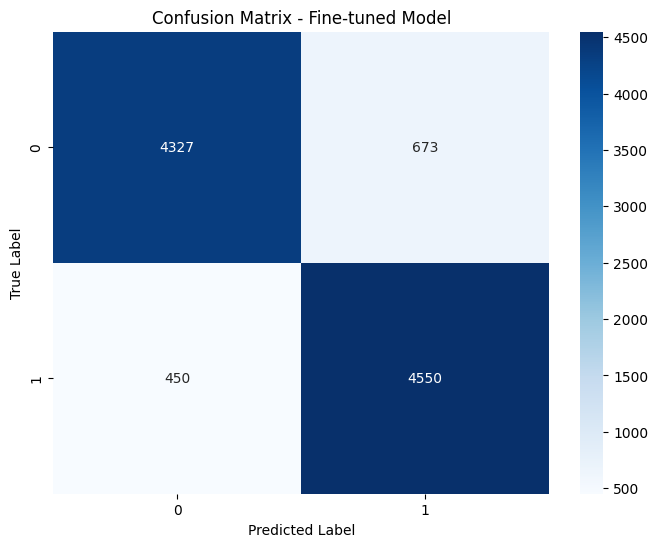

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm_ft, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Fine-tuned Model')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.savefig('confusion_matrix_finetuned.png')

### Task 6

In [ ]:
from sklearn.metrics import classification_report, f1_score, accuracy_score

# Fine-tuned
print("=== Fine-tuned Model ===")
print(classification_report(test_labels, y_pred_ft))
f1_ft = f1_score(test_labels, y_pred_ft, average='macro')
acc_ft = accuracy_score(test_labels, y_pred_ft)

# Baseline (если есть)
if baseline_model:
    preds_baseline_all = predict_baseline(test_texts, baseline_model, vectorizer)
    y_pred_base = [p['prediction'] for p in preds_baseline_all]

    print("\n=== Baseline Model ===")
    print(classification_report(test_labels, y_pred_base))
    f1_base = f1_score(test_labels, y_pred_base, average='macro')
    acc_base = accuracy_score(test_labels, y_pred_base)

    print(f'\n=== Сравнение ===')
    print(f'Fine-tuned F1: {f1_ft:.4f}, Accuracy: {acc_ft:.4f}')
    print(f'Baseline F1: {f1_base:.4f}, Accuracy: {acc_base:.4f}')
    print(f'Улучшение F1: {(f1_ft - f1_base) / f1_base * 100:.2f}%')

=== Fine-tuned Model ===
              precision    recall  f1-score   support

           0       0.91      0.87      0.89      5000
           1       0.87      0.91      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



Extracting CLS embeddings:   0%|          | 0/79 [00:00<?, ?it/s]


=== Baseline Model ===
              precision    recall  f1-score   support

           0       0.81      0.83      0.82      5000
           1       0.83      0.81      0.82      5000

    accuracy                           0.82     10000
   macro avg       0.82      0.82      0.82     10000
weighted avg       0.82      0.82      0.82     10000


=== Сравнение ===
Fine-tuned F1: 0.8876, Accuracy: 0.8877
Baseline F1: 0.8211, Accuracy: 0.8211
Улучшение F1: 8.11%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


### Task 7

In [ ]:
with open('comparison_results.txt', 'w') as f:
    f.write('=== Сравнение моделей ===\n\n')
    f.write(f'Fine-tuned Model:\n')
    f.write(f'  F1 (macro): {f1_ft:.4f}\n')
    f.write(f'  Accuracy: {acc_ft:.4f}\n')

    if baseline_model:
        f.write(f'\nBaseline Model:\n')
        f.write(f'  F1 (macro): {f1_base:.4f}\n')
        f.write(f'  Accuracy: {acc_base:.4f}\n')
        f.write(f'\nУлучшение: {(f1_ft - f1_base) / f1_base * 100:.2f}%\n')

# Day 7

### Task 1

In [ ]:
import pandas as pd

# Загрузите данные и предсказания из Дня 6
df_test = pd.DataFrame({
    'text': test_texts,
    'true_label': test_labels,
    'pred_label': y_pred_ft
})

# Найдите ошибки
errors = df_test[df_test['true_label'] != df_test['pred_label']]

# False Positives (предсказала positive, а было negative/neutral)
fp = errors[(errors['pred_label'] == 1) & (errors['true_label'] == 0)]

# False Negatives (предсказала negative, а было positive)
fn = errors[(errors['pred_label'] == 0) & (errors['true_label'] == 1)]

print(f'Всего ошибок: {len(errors)}')
print(f'False Positives: {len(fp)}')
print(f'False Negatives: {len(fn)}')

Всего ошибок: 1123
False Positives: 673
False Negatives: 450


### Task 2

In [ ]:
print("\n=== FALSE POSITIVES (сказали good, а было bad) ===")
for idx, row in fp.head(5).iterrows():
    print(f'\nТекст: {row["text"][:100]}...')
    print(f'Истинный класс: {row["true_label"]}, Предсказан: {row["pred_label"]}')

print("\n=== FALSE NEGATIVES (сказали bad, а было good) ===")
for idx, row in fn.head(5).iterrows():
    print(f'\nТекст: {row["text"][:100]}...')
    print(f'Истинный класс: {row["true_label"]}, Предсказан: {row["pred_label"]}')


=== FALSE POSITIVES (сказали good, а было bad) ===

Текст: Its a sin how these things are made, but then again we wouldn't get to see the best "Dummy scene" ev...
Истинный класс: 0, Предсказан: 1

Текст: I finally rented this video after searching for it for many months. Initially I only wanted to see i...
Истинный класс: 0, Предсказан: 1

Текст: It's important to keep in mind the real meaning of the phrase "Inspired by a true story" when watchi...
Истинный класс: 0, Предсказан: 1

Текст: A Cinderella story made for adults who live in dreamland. The romance is very unrealistic, fluttery,...
Истинный класс: 0, Предсказан: 1

Текст: I am sorry to rain on everybody's parade. Just a little background about me: I like and know a lot a...
Истинный класс: 0, Предсказан: 1

=== FALSE NEGATIVES (сказали bad, а было good) ===

Текст: This Movie is a warning to all people sat surfing the internet on a typical day at the office. My Wa...
Истинный класс: 1, Предсказан: 0

Текст: (WARNING - CONTAIN

In [ ]:
errors['text_length'] = errors['text'].str.len()
print(f'\nСредняя длина ошибочных текстов: {errors["text_length"].mean():.0f}')
print(f'Средняя длина всех текстов: {df_test["text"].str.len().mean():.0f}')


Средняя длина ошибочных текстов: 1581
Средняя длина всех текстов: 1314


/tmp/ipykernel_942/2375809873.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  errors['text_length'] = errors['text'].str.len()


In [ ]:
with open('error_analysis.txt', 'w') as f:
    f.write('=== АНАЛИЗ ОШИБОК ===\n\n')
    f.write(f'Всего ошибок: {len(errors)}\n')
    f.write(f'False Positives: {len(fp)}\n')
    f.write(f'False Negatives: {len(fn)}\n\n')

    f.write('=== ПРИМЕРЫ FALSE POSITIVES ===\n')
    for idx, row in fp.head(5).iterrows():
        f.write(f'\nТекст: {row["text"]}\n')
        f.write(f'Истинный: {row["true_label"]}, Предсказан: {row["pred_label"]}\n')

    f.write('\n\n=== ПРИМЕРЫ FALSE NEGATIVES ===\n')
    for idx, row in fn.head(5).iterrows():
        f.write(f'\nТекст: {row["text"]}\n')
        f.write(f'Истинный: {row["true_label"]}, Предсказан: {row["pred_label"]}\n')

    # Добавьте ваши наблюдения
    f.write('\n\n=== НАБЛЮДЕНИЯ ===\n')
    f.write('Добавьте сюда ваши выводы о паттернах ошибок...\n')